# Week 4 — Task 2: Gaussian smoothing + 3×3 Prewitt-y filter

> *2. `[[-1 -1 -1], [0 0 0], [1 1 1]]` 3x3 Prewitt filtresini gri tonlamalı bir görüntü üzerinde test ediniz. Filtreyi görüntü üzerinde çalıştırmadan önce Gauss filtresi ile görüntüyü hafif yumuşatınız.*

**Test image:** SpaceX Falcon 9 launch photo (`assets/rocket.jpg`, public domain, from scikit-image 0.25.2 sample data — see `assets/sources.json`). Same image as Task 1, so the two results can be compared directly. Its strongest structures are vertical, so this kernel will show much *less* — which is the point: it only sees **horizontal** edges (tower cross-beams, the launch platform, the rocket's nose and interstage).

Pipeline: **color → grayscale → Gaussian (5×5, σ = 1) → Prewitt-y → |response| for display**.

The notebook runs on the CPU everywhere. If OpenCV was built with CUDA (see `week1/01_cuda_opencv_colab_setup.ipynb`) and a GPU is visible, Section 7 repeats the pipeline on the GPU and compares the results.

## 1. Setup

**On Colab with a GPU:** each notebook gets its own runtime, so the CUDA build from the Week 1 notebook is not automatically here. The next cell looks for it in this order: already installed at `/opt/opencv-cuda` → the Google Drive cache written by the Week 1 notebook (`USE_DRIVE = True`). If neither exists it simply uses the normal CPU-only OpenCV. **Run this cell before anything imports `cv2`.**

In [1]:
import os, sys, glob, subprocess

CUDA_PREFIX = "/opt/opencv-cuda"
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.isdir(f"{CUDA_PREFIX}/python"):
    has_gpu = subprocess.run("nvidia-smi", shell=True, capture_output=True).returncode == 0
    if has_gpu:
        from google.colab import drive
        drive.mount("/content/drive")
        pyver = f"{sys.version_info.major}.{sys.version_info.minor}"
        caches = sorted(glob.glob(f"/content/drive/MyDrive/opencv_cuda_cache/opencv-*-py{pyver}.tar.gz"))
        if caches:
            os.makedirs(CUDA_PREFIX, exist_ok=True)
            subprocess.run(["tar", "-xzf", caches[-1], "-C", CUDA_PREFIX], check=True)
            print("Restored CUDA OpenCV from", caches[-1])
        else:
            print("No Drive cache found → CPU only. Run week1/01_cuda_opencv_colab_setup.ipynb with USE_DRIVE = True first.")

if os.path.isdir(f"{CUDA_PREFIX}/python"):
    sys.path.insert(0, f"{CUDA_PREFIX}/python")   # take precedence over the CPU-only pip wheel
    print("Using CUDA build from", CUDA_PREFIX)

In [2]:
from pathlib import Path
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Works when run from the repo root, from week4/, or on Colab (downloads the image if missing)
HERE = Path("week4") if Path("week4/assets").exists() else Path(".")
IMG = HERE / "assets" / "rocket.jpg"
if not IMG.exists():
    import urllib.request
    IMG.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.2/skimage/data/rocket.jpg", IMG)
OUT = HERE / "results"
OUT.mkdir(exist_ok=True)
print("OpenCV", cv2.__version__, "| image:", IMG)

OpenCV 5.0.0 | image: assets/rocket.jpg


## 2. Load and convert to grayscale

`cv2.imread` returns **BGR** (not RGB). `cv2.cvtColor(..., COLOR_BGR2GRAY)` computes `Y = 0.299·R + 0.587·G + 0.114·B` — green weighs most because human eyes are most sensitive to it.

We then switch to **float32**: the Prewitt output can be negative, and `uint8` cannot hold negative numbers (it would clip them to 0 and you would lose half of the edges).

In [3]:
bgr = cv2.imread(str(IMG), cv2.IMREAD_COLOR)
assert bgr is not None, f"could not read {IMG}"
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
gray_f = gray.astype(np.float32)
print("color:", bgr.shape, bgr.dtype, "| gray:", gray.shape, gray.dtype, "range", gray.min(), "-", gray.max())

color: (427, 640, 3) uint8 | gray: (427, 640) uint8 range 0 - 255


## 3. Light Gaussian smoothing

**Why smooth first?** A derivative filter amplifies *any* rapid change — including sensor noise and JPEG artifacts. Prewitt-y computes, for each pixel, *(sum of the 3 pixels below) − (sum of the 3 pixels above)*. Random pixel-to-pixel noise produces many small fake "edges". A Gaussian blur averages neighbours with bell-shaped weights, suppressing that high-frequency noise while keeping the large, real edges.

**"Hafif" (light)** = small kernel, small σ. We use **5×5, σ = 1.0**. Larger σ would also blur real edges and make them wide and weak.

1-D Gaussian weights for σ = 1, size 5 (the 2-D kernel is the outer product of this with itself):

In [4]:
KSIZE, SIGMA = (5, 5), 1.0
g1d = cv2.getGaussianKernel(KSIZE[0], SIGMA).ravel()
print("1-D weights:", np.round(g1d, 4), " sum =", g1d.sum().round(6))
print("2-D kernel:\n", np.round(np.outer(g1d, g1d), 4))

smooth = cv2.GaussianBlur(gray_f, KSIZE, SIGMA, borderType=cv2.BORDER_REFLECT_101)

1-D weights: [0.0545 0.2442 0.4026 0.2442 0.0545]  sum = 1.0
2-D kernel:
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]


## 4. The Prewitt kernel

```
      [-1 -1 -1]
K  =  [ 0  0  0]
      [ 1  1  1]
```

* This is the **transpose** of the Task 1 kernel. Each column is a central difference `f(y+1) − f(y−1)` → approximates the vertical derivative ∂I/∂y (image rows grow downward).
* Adding the **three** columns is a small horizontal average → some built-in noise resistance.
* It responds to intensity changes **along y**, so it highlights **horizontal edges**. Vertical edges give ~0.
* Weights sum to 0 → a flat region gives exactly 0.
* Sign: **positive** = dark→bright going **down**, **negative** = bright→dark going down.

**Correlation vs. convolution:** `cv2.filter2D` performs *correlation* (it does not flip the kernel). True convolution would flip K up↔down, which for this kernel only flips the sign of the output. We use `filter2D` with K as written, so a positive value means "brighter below".

`ddepth=cv2.CV_32F` keeps the negative values.

In [5]:
K = np.array([[-1, -1, -1],
              [ 0,  0,  0],
              [ 1,  1,  1]], dtype=np.float32)

prewitt_smooth = cv2.filter2D(smooth, cv2.CV_32F, K, borderType=cv2.BORDER_REFLECT_101)
prewitt_raw    = cv2.filter2D(gray_f, cv2.CV_32F, K, borderType=cv2.BORDER_REFLECT_101)   # no blur, for comparison

print("signed response range:", prewitt_smooth.min(), "to", prewitt_smooth.max(),
      "(theoretical limit ±765 = 3 × 255)")

signed response range: -271.01437 to 249.17511 (theoretical limit ±765 = 3 × 255)


## 5. Check: our own NumPy implementation must give the same numbers

Writing the filter by hand once is the best way to understand it. Pad the image with the same border rule (`BORDER_REFLECT_101` ↔ NumPy `mode="reflect"`), then add the 9 shifted copies weighted by K.

In [6]:
def correlate3x3(img, k):
    p = np.pad(img, 1, mode="reflect")          # same as BORDER_REFLECT_101
    h, w = img.shape
    out = np.zeros_like(img, dtype=np.float32)
    for dy in range(3):
        for dx in range(3):
            if k[dy, dx] != 0:
                out += k[dy, dx] * p[dy:dy + h, dx:dx + w]
    return out

manual = correlate3x3(smooth, K)
print("max |manual − cv2.filter2D| =", float(np.abs(manual - prewitt_smooth).max()))
assert np.allclose(manual, prewitt_smooth, atol=1e-3)

# Tiny example you can verify on paper: a top→bottom step edge 10 → 50
step = np.array([[10] * 3, [10] * 3, [50] * 3, [50] * 3], dtype=np.float32)
print(step)
print(cv2.filter2D(step, cv2.CV_32F, K, borderType=cv2.BORDER_REFLECT_101))

max |manual − cv2.filter2D| = 0.0
[[10. 10. 10.]
 [10. 10. 10.]
 [50. 50. 50.]
 [50. 50. 50.]]
[[  0.   0.   0.]
 [120. 120. 120.]
 [120. 120. 120.]
 [  0.   0.   0.]]


In the tiny example the two middle **rows** each get `3 × (50 − 10) = 120`: the horizontal edge between them is detected. The border rows are 0 because reflection copies the neighbour value. The same step turned 90° (Task 1's example) would give 0 everywhere with this kernel.

## 6. Results

For display we take the **absolute value** (edge strength regardless of direction) and scale it to 0–255. The signed map is shown with a diverging colormap: red = dark→bright going down, blue = bright→dark going down.

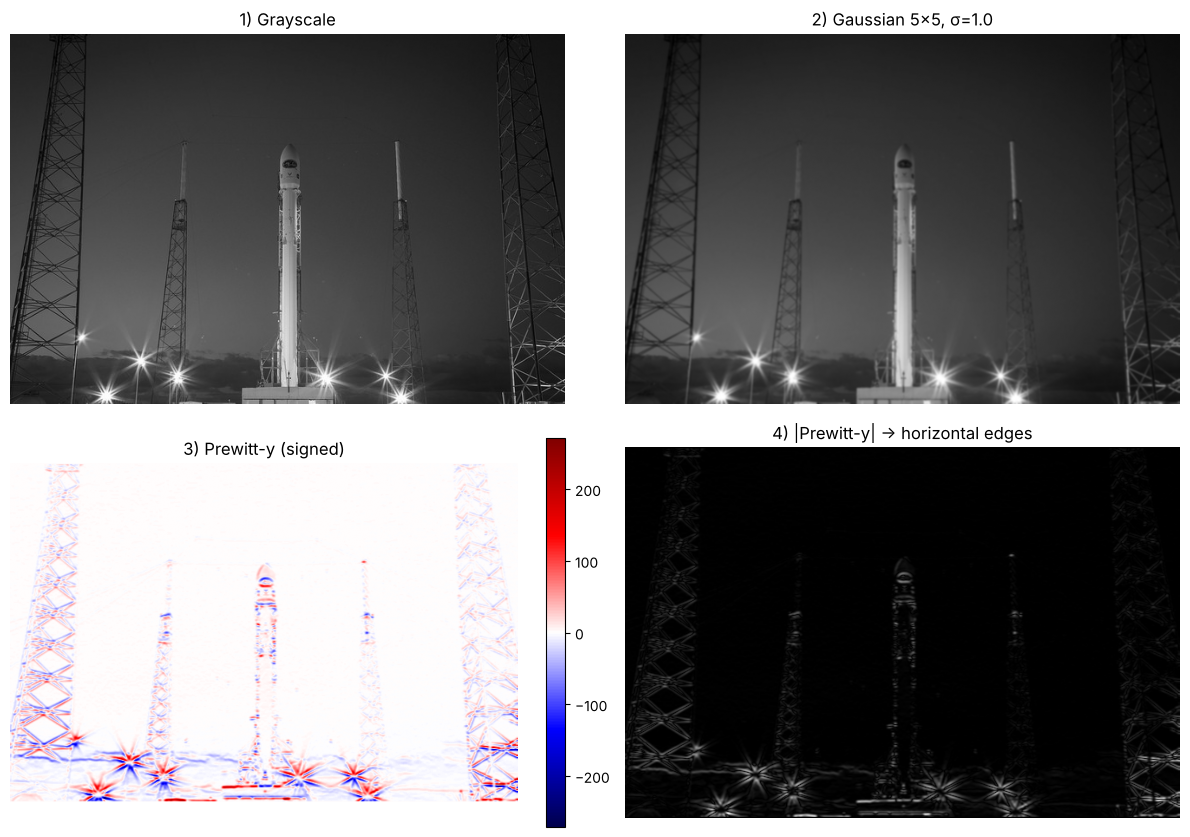

In [7]:
def to_u8(a):
    return cv2.normalize(np.abs(a), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

mag_smooth, mag_raw = to_u8(prewitt_smooth), to_u8(prewitt_raw)
cv2.imwrite(str(OUT / "task2_01_gray.png"), gray)
cv2.imwrite(str(OUT / "task2_02_gauss.png"), np.clip(smooth, 0, 255).astype(np.uint8))
cv2.imwrite(str(OUT / "task2_03_prewitt_y_gauss.png"), mag_smooth)
cv2.imwrite(str(OUT / "task2_04_prewitt_y_no_gauss.png"), mag_raw)

lim = np.abs(prewitt_smooth).max()
fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
ax[0, 0].imshow(gray, cmap="gray"); ax[0, 0].set_title("1) Grayscale")
ax[0, 1].imshow(smooth, cmap="gray"); ax[0, 1].set_title(f"2) Gaussian {KSIZE[0]}×{KSIZE[1]}, σ={SIGMA}")
im = ax[1, 0].imshow(prewitt_smooth, cmap="seismic", vmin=-lim, vmax=lim)
ax[1, 0].set_title("3) Prewitt-y (signed)"); fig.colorbar(im, ax=ax[1, 0], fraction=0.035)
ax[1, 1].imshow(mag_smooth, cmap="gray"); ax[1, 1].set_title("4) |Prewitt-y| → horizontal edges")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task2_05_pipeline.png", dpi=110); plt.show()

### Does the Gaussian step matter? Add noise and compare

The photo is fairly clean, so the difference is subtle. To make the point visible we add Gaussian noise (σ = 15 gray levels) and run Prewitt with and without the blur.

* **noise** = mean |response| inside a flat sky patch (top-left corner, no real edges) — everything there is noise;
* **edges** = 99.5th percentile of |response| over the whole image ≈ the strong, real edges;
* **edge/noise** = how clearly the edges stand out. Higher is better.

case              noise (sky mean)  edges (99.5th pct)  edge/noise
clean, no blur                6.04               193.0        32.0
clean, Gauss                  3.14               102.8        32.8
noisy, no blur               30.59               202.9         6.6
noisy, Gauss                 11.04               103.7         9.4


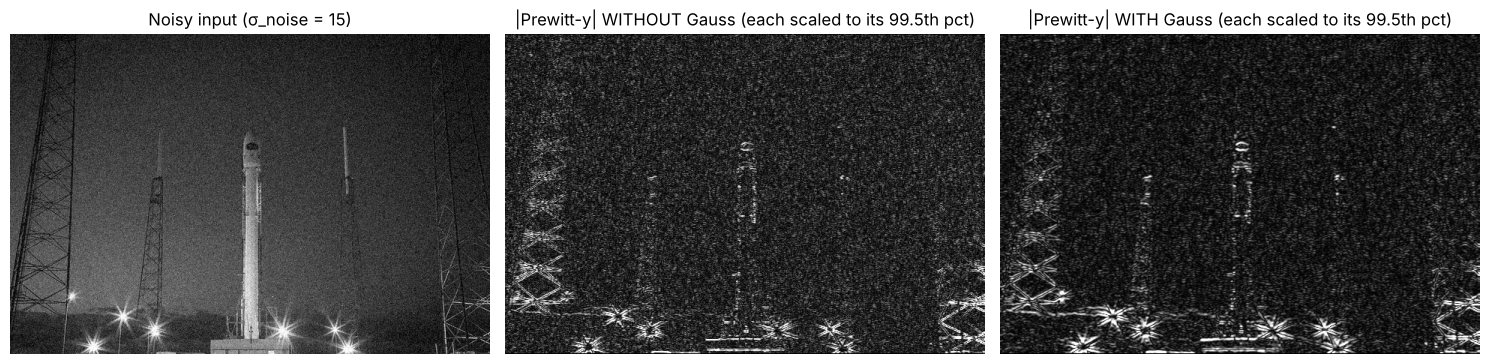

In [8]:
rng = np.random.default_rng(42)
noisy = np.clip(gray_f + rng.normal(0, 15, gray_f.shape), 0, 255).astype(np.float32)

p_noisy_raw   = cv2.filter2D(noisy, cv2.CV_32F, K)
p_noisy_gauss = cv2.filter2D(cv2.GaussianBlur(noisy, KSIZE, SIGMA), cv2.CV_32F, K)

sky = (slice(10, 110), slice(10, 160))       # flat region, no real edges
print(f"{'case':16s} {'noise (sky mean)':>17s} {'edges (99.5th pct)':>19s} {'edge/noise':>11s}")
for name, r in [("clean, no blur", prewitt_raw), ("clean, Gauss", prewitt_smooth),
                ("noisy, no blur", p_noisy_raw), ("noisy, Gauss", p_noisy_gauss)]:
    noise, edge = np.abs(r[sky]).mean(), np.percentile(np.abs(r), 99.5)
    print(f"{name:16s} {noise:17.2f} {edge:19.1f} {edge / noise:11.1f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].imshow(noisy, cmap="gray"); ax[0].set_title("Noisy input (σ_noise = 15)")
for a, r, t in [(ax[1], p_noisy_raw, "|Prewitt-y| WITHOUT Gauss"), (ax[2], p_noisy_gauss, "|Prewitt-y| WITH Gauss")]:
    a.imshow(np.abs(r), cmap="gray", vmax=np.percentile(np.abs(r), 99.5)); a.set_title(t + " (each scaled to its 99.5th pct)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task2_06_noise_comparison.png", dpi=110); plt.show()

## 7. Same pipeline on the GPU (OpenCV CUDA)

Runs only if `cv2.cuda` reports a device. Notes:

* `cv2.cuda.createLinearFilter` only allows **output type = input type**, so we upload the **float32** image — a `uint8` → `uint8` filter would clip the negative half of the Prewitt response.
* Filters are created once, then `.apply()` is called on a `GpuMat`.
* Timing excludes the first call (CUDA context + kernel warm-up) and includes upload/download, because that is what you really pay.

In [9]:
has_cuda = hasattr(cv2, "cuda") and cv2.cuda.getCudaEnabledDeviceCount() > 0
print("CUDA devices visible to OpenCV:", cv2.cuda.getCudaEnabledDeviceCount() if hasattr(cv2, "cuda") else 0)

if not has_cuda:
    print("No CUDA build / GPU → skipped. Run week1/01_cuda_opencv_colab_setup.ipynb on a Colab GPU runtime first.")
else:
    gauss_gpu   = cv2.cuda.createGaussianFilter(cv2.CV_32FC1, cv2.CV_32FC1, KSIZE, SIGMA)
    prewitt_gpu = cv2.cuda.createLinearFilter(cv2.CV_32FC1, cv2.CV_32FC1, K)

    def gpu_pipeline(img):
        g = cv2.cuda.GpuMat(); g.upload(img)
        return prewitt_gpu.apply(gauss_gpu.apply(g)).download()

    def cpu_pipeline(img):
        return cv2.filter2D(cv2.GaussianBlur(img, KSIZE, SIGMA), cv2.CV_32F, K)

    out_gpu = gpu_pipeline(gray_f)
    diff = np.abs(out_gpu - prewitt_smooth)
    print(f"max |GPU − CPU| = {diff.max():.4f}   (mean {diff.mean():.6f})")
    cv2.imwrite(str(OUT / "task2_07_prewitt_y_gauss_gpu.png"), to_u8(out_gpu))

    def bench(fn, img, n=50):
        fn(img)                                   # warm-up
        t = time.perf_counter()
        for _ in range(n): fn(img)
        return (time.perf_counter() - t) / n * 1e3

    big = cv2.resize(gray_f, (3840, 2160))       # 4K: where a GPU starts to pay off
    for name, img in [("640×427", gray_f), ("3840×2160", big)]:
        print(f"{name:10s}  CPU {bench(cpu_pipeline, img):7.2f} ms   GPU (incl. upload/download) {bench(gpu_pipeline, img):7.2f} ms")

CUDA devices visible to OpenCV: 0
No CUDA build / GPU → skipped. Run week1/01_cuda_opencv_colab_setup.ipynb on a Colab GPU runtime first.


## 8. What to notice

* Compared with Task 1, the long vertical sides of the rocket and the tower legs almost disappear; what remains are horizontal pieces — tower cross-beams, the launch platform, the nose cone, the light flares' horizontal rays. Each kernel is blind to edges parallel to its own difference direction. The towers' **diagonal** braces show up in both tasks, because a diagonal edge changes along x *and* y.
* Blurring lowers **both** numbers: noise in flat areas and the height of real edges (a blurred edge is less steep). What improves is their **ratio** — clearly on the noisy image, only slightly on the clean photo. That is the trade-off behind "hafif" smoothing: enough σ to kill noise, not so much that edges get wide and weak.
* On the GPU, results match the CPU up to floating-point rounding; the speed-up only appears for large images, because upload/download dominates for small ones.

## 9. Bonus: combine Task 1 and Task 2 → all edges

Prewitt-x (`Gx`) and Prewitt-y (`Gy`) are the two components of the image **gradient**. Its length `√(Gx² + Gy²)` is the edge strength in *any* direction, and `atan2(Gy, Gx)` is the direction. This is the full Prewitt edge detector.

Kx (Task 1):
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]


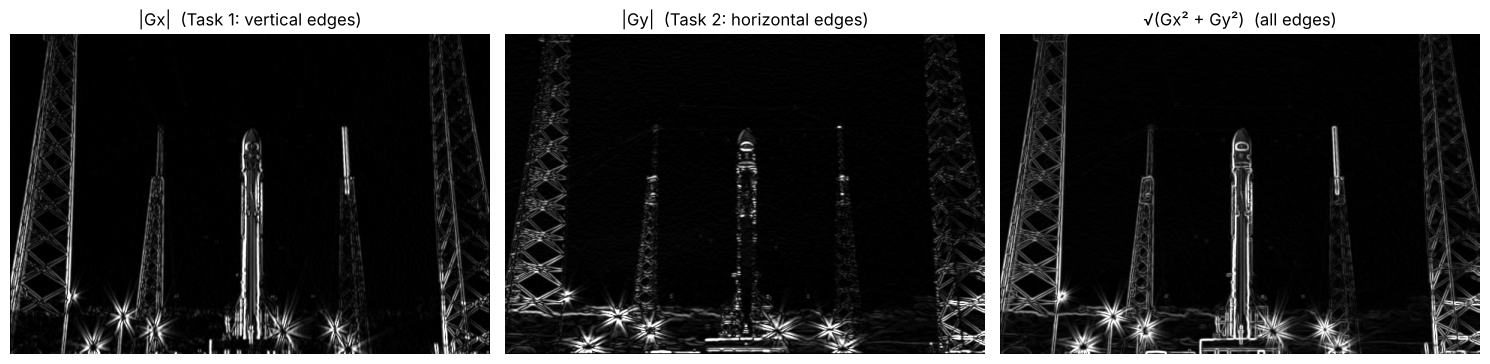

In [10]:
Kx = K.T                                   # Task 1 kernel = transpose of this one
gx = cv2.filter2D(smooth, cv2.CV_32F, Kx)
gy = prewitt_smooth
mag = cv2.magnitude(gx, gy)
print("Kx (Task 1):\n", Kx)
cv2.imwrite(str(OUT / "task2_08_gradient_magnitude.png"), to_u8(mag))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, img, t in [(ax[0], gx, "|Gx|  (Task 1: vertical edges)"),
                  (ax[1], gy, "|Gy|  (Task 2: horizontal edges)"),
                  (ax[2], mag, "√(Gx² + Gy²)  (all edges)")]:
    a.imshow(np.abs(img), cmap="gray", vmax=np.percentile(np.abs(img), 99.5)); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "task2_09_x_y_magnitude.png", dpi=110); plt.show()